# Generation of Supplementary Information Data Analyses 

## Overview
This notebook reproduces the primary data analyses presented in Supplementary Information of our manuscript, *"The potential and viability of V2G for California EV drivers"*.

## Libraries and Setup

In [2]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import scipy.stats as st
import warnings
from scipy.stats import ttest_ind, t
from statsmodels.stats.multitest import multipletests
from scipy.stats import mannwhitneyu


# Suppress minor pandas warnings for clean notebook execution
warnings.filterwarnings('ignore')

# Data 

In [3]:
results_df = pd.read_csv('../data/california_bev_battery_degradation_simulation_results.csv')
results_df

,vehicle_id,cluster,q_loss_LFP|Gr_10_years,q_loss_cyc_LFP|Gr_10_years,q_loss_cal_LFP|Gr_10_years,q_loss_NMC|Gr B1_10_years,q_loss_cyc_NMC|Gr B1_10_years,q_loss_cal_NMC|Gr B1_10_years,q_loss_NMC|Gr B2_10_years,q_loss_cyc_NMC|Gr B2_10_years,...,delta_q_loss_LFP|Gr_10_years,delta_q_loss_cyc_LFP|Gr_10_years,delta_q_loss_cal_LFP|Gr_10_years,delta_q_loss_NMC|Gr B1_10_years,delta_q_loss_cyc_NMC|Gr B1_10_years,delta_q_loss_cal_NMC|Gr B1_10_years,delta_q_loss_NMC|Gr B2_10_years,delta_q_loss_cyc_NMC|Gr B2_10_years,delta_q_loss_cal_NMC|Gr B2_10_years,V2G_kwh_10_years
0,0,0,6.846279,4.002871,2.843409,13.949890,2.197217,11.752672,5.879810,2.059128,...,-0.458312,-0.567448,0.109137,0.342753,-0.119793,0.462546,-0.122799,-0.316951,0.194152,10821.36
1,1,3,4.673586,2.752955,1.920631,10.744970,2.735554,8.009415,4.277929,1.925591,...,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,0.00
2,2,1,5.510617,3.082581,2.428036,11.672900,2.083842,9.589058,4.247546,1.402647,...,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,0.00
3,3,0,9.506368,7.214909,2.291459,8.965488,2.407599,6.557889,4.866640,2.103478,...,-0.372897,-0.408039,0.035142,0.167620,0.004523,0.163097,-0.099939,-0.170969,0.071030,7053.60
4,4,3,4.392786,1.984613,2.408174,11.813082,1.996731,9.816351,4.225082,1.223307,...,0.029191,0.016273,0.012918,0.112670,0.058687,0.053983,0.060643,0.039387,0.021256,28.56
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
310,310,2,5.095129,2.216411,2.878718,12.558043,1.529224,11.028819,4.229954,0.800333,...,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,0.00
311,311,1,4.408061,2.257766,2.150295,10.904760,2.422791,8.481969,3.742655,1.313861,...,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,0.00
312,312,0,7.481869,4.410115,3.071754,14.775629,2.520803,12.254826,6.332286,2.406093,...,-0.551716,-0.787757,0.236041,0.781463,-0.183725,0.965188,-0.091834,-0.489162,0.397328,14905.92
313,313,3,5.451682,3.220131,2.231551,11.864274,2.383082,9.481192,4.847518,1.886269,...,-0.094150,-0.151935,0.057785,0.282656,0.030798,0.251858,0.061807,-0.040324,0.102131,2735.16


### Vehicle Usage Behavior Clustering and Nomenclature

The results from applying clustering method, outlined in Section 3.2, to identified driver “profiles” from the real-world BEV data assigns a numeric label (`0`, `1`, `2`, `3`) to each vehicle as shown in column `cluster`. To make the context of the column `cluster`, we map the results to descriptive behavioral profiles based on the characteristics of each cluster.

**Cluster Mapping:**

| Cluster| Behavioral Profile | Key Characteristics |
| :--- | :--- | :--- |
| `0` | **Daily Charger** | *Drivers who consistently charge nightly, maintaining a high average State of Charge (SOC). * |
| `1` | **Public Charger** | *Drivers relying on public charging infrastructure, often fast charging* |
| `2` | **BEV 2nd vehicle** | *Drivers with lower utilization rates, typically charging when SOC reaches thresholds.* |
| `3` | **Threshold Charger** | *Daily users who charge only when meeting a threshold rather than every day.* |




In [5]:

cluster_mapping = {
    0: "Daily Charger",
    1: "Public Charger",
    2: "BEV 2nd vehicle",
    3: "Threshold Charger"
}

results_df['cluster_profile'] = results_df['cluster'].map(cluster_mapping)
results_df

,vehicle_id,cluster,q_loss_LFP|Gr_10_years,q_loss_cyc_LFP|Gr_10_years,q_loss_cal_LFP|Gr_10_years,q_loss_NMC|Gr B1_10_years,q_loss_cyc_NMC|Gr B1_10_years,q_loss_cal_NMC|Gr B1_10_years,q_loss_NMC|Gr B2_10_years,q_loss_cyc_NMC|Gr B2_10_years,...,delta_q_loss_cyc_LFP|Gr_10_years,delta_q_loss_cal_LFP|Gr_10_years,delta_q_loss_NMC|Gr B1_10_years,delta_q_loss_cyc_NMC|Gr B1_10_years,delta_q_loss_cal_NMC|Gr B1_10_years,delta_q_loss_NMC|Gr B2_10_years,delta_q_loss_cyc_NMC|Gr B2_10_years,delta_q_loss_cal_NMC|Gr B2_10_years,V2G_kwh_10_years,cluster_profile
0,0,0,6.846279,4.002871,2.843409,13.949890,2.197217,11.752672,5.879810,2.059128,...,-0.567448,0.109137,0.342753,-0.119793,0.462546,-0.122799,-0.316951,0.194152,10821.36,Daily Charger
1,1,3,4.673586,2.752955,1.920631,10.744970,2.735554,8.009415,4.277929,1.925591,...,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,0.00,Threshold Charger
2,2,1,5.510617,3.082581,2.428036,11.672900,2.083842,9.589058,4.247546,1.402647,...,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,0.00,Public Charger
3,3,0,9.506368,7.214909,2.291459,8.965488,2.407599,6.557889,4.866640,2.103478,...,-0.408039,0.035142,0.167620,0.004523,0.163097,-0.099939,-0.170969,0.071030,7053.60,Daily Charger
4,4,3,4.392786,1.984613,2.408174,11.813082,1.996731,9.816351,4.225082,1.223307,...,0.016273,0.012918,0.112670,0.058687,0.053983,0.060643,0.039387,0.021256,28.56,Threshold Charger
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
310,310,2,5.095129,2.216411,2.878718,12.558043,1.529224,11.028819,4.229954,0.800333,...,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,0.00,BEV 2nd vehicle
311,311,1,4.408061,2.257766,2.150295,10.904760,2.422791,8.481969,3.742655,1.313861,...,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,-0.000000,0.00,Public Charger
312,312,0,7.481869,4.410115,3.071754,14.775629,2.520803,12.254826,6.332286,2.406093,...,-0.787757,0.236041,0.781463,-0.183725,0.965188,-0.091834,-0.489162,0.397328,14905.92,Daily Charger
313,313,3,5.451682,3.220131,2.231551,11.864274,2.383082,9.481192,4.847518,1.886269,...,-0.151935,0.057785,0.282656,0.030798,0.251858,0.061807,-0.040324,0.102131,2735.16,Threshold Charger


## Supplementary Table 1

To assess if battery design is dominated by calendar aging or cycle aging. Wilcoxon signed-rank test for each battery design, where $H_0$: median (calendar aging)/(total capacity loss) = 0.5, and $H_1$: median (calendar aging)/(total capacity loss) $\ne$ 0.5

In [ ]:
# Initialize a list to hold the statistical records
cal_aging_proportion_records= []
cyc_aging_proportion_records= []
p_value_records= []

chemistry_array  = ["LFP|Gr", "NMC|Gr B1", "NMC|Gr B2"]


for chemistry in chemistry_array:
    # Calculate the fraction of capacity loss due to calendar aging
    cal_fraction = (results_df[f'q_loss_cal_{chemistry}_10_years'] / 
                    results_df[f'q_loss_{chemistry}_10_years']).dropna().to_numpy()

    n = len(cal_fraction)
    if n == 0:
        continue

    # 1. Descriptive Statistics
    mean_val = np.mean(cal_fraction)
    sem = np.std(cal_fraction, ddof=1) / np.sqrt(n)

    # 2. Perform the Wilcoxon signed-rank test against a median of 0.5
    w_stat, p_value = st.wilcoxon(cal_fraction - 0.5)

    # 3. 95% Confidence Interval Calculation
    alpha = 0.05                       
    t_crit = st.t.ppf(1 - alpha/2, df=n-1)         
    ci_low = mean_val - t_crit * sem
    ci_high = mean_val + t_crit * sem

    # Append results to the records list
    
    cal_aging_proportion_records.append({
        'Chemistry': chemistry,
        'Mean': round(mean_val,3),
        '95% CI Lower': round(ci_low,3),
        '95% CI Upper': round(ci_high,3),
    })

    cyc_aging_proportion_records.append({
        'Chemistry': chemistry,
        'Mean': round(1-mean_val,3),
        '95% CI Lower': round(1-ci_high,3),
        '95% CI Upper': round(1-ci_low,3),
    })
    p_value_records.append({
        'Chemistry': chemistry,
        'p-value': p_value,

    })

print ('(Calendar Aging)/(Total Capacity Loss)')
# Compile into a final DataFrame
cal_aging_proportion_df = pd.DataFrame(cal_aging_proportion_records).set_index('Chemistry')
display(cal_aging_proportion_df)

print ('(Cycle Aging)/(Total Capacity Loss)')
cyc_aging_proportion_df = pd.DataFrame(cyc_aging_proportion_records).set_index('Chemistry')
display(cyc_aging_proportion_df)

p_value_df = pd.DataFrame(p_value_records).set_index('Chemistry')
display(p_value_df)

## Supplementary Table 2

To support for LFP|Gr: *"Public Charger" have statistically significantly higher capacity loss than other vehicle usage behaviors*

Mann–Whitney U test

Let $\mu_P$ = mean capacity loss of "Public Charger", $\mu_O$ = mean capacity loss of other behavior.

$H_0$: $\mu_P \leq \mu_O$,  $H_1$: $\mu_P > \mu_O$

In [ ]:

chemistry = "LFP|Gr"
target_cluster = 'Public Charger'
comparisons = ['Daily Charger','BEV 2nd vehicle', 'Threshold Charger']
a = results_df[results_df['cluster_profile']==target_cluster][f'q_loss_{chemistry}_10_years'].to_numpy()

rows = []
for cluster in comparisons:
    x = results_df[results_df['cluster_profile']==cluster][f'q_loss_{chemistry}_10_years'].to_numpy()
    
    # Sample sizes and means for the table
    n_P, n_O = len(a), len(x)
    mu_P, mu_O = a.mean(), x.mean()

          # ---------- Mann-Whitney one-sided test ----------
    alternative = 'greater' if mu_P > mu_O else 'less'
    u_stat, p_val = mannwhitneyu(a, x, alternative=alternative)

    rows.append({
        "H1": f"mu_P > mu_O (vs. {cluster})",
        "n_P": n_P,
        "n_O": n_O,
        "mu_P (%)": round(mu_P, 2),
        "mu_O (%)": round(mu_O, 2),
        "U_stat": int(u_stat),
        "p_value": f"{p_val:.2E}"
    })

# Results in Supplementary Table 3
cols = ["H1", "n_P", "n_O", "mu_P (%)", "mu_O (%)", "U_stat", "p_value"]
result_table = pd.DataFrame(rows, columns=cols)
display(result_table)

## Supplementary Table 3

To support for NMC|Gr B1: *"Daily Charger" have statistically significantly higher capacity loss than other vehicle usage behaviors*

Mann–Whitney U test

Let $\mu_D$ = mean capacity loss of "Daily Charger", $\mu_O$ = mean capacity loss of other behavior.

$H_0$: $\mu_D \leq \mu_O$,  $H_1$: $\mu_D > \mu_O$

In [ ]:

chemistry = "NMC|Gr B1"
target_cluster = 'Daily Charger'
comparisons = ['Public Charger', 'BEV 2nd vehicle', 'Threshold Charger']
a = results_df[results_df['cluster_profile']==target_cluster][f'q_loss_{chemistry}_10_years'].to_numpy()

rows = []
for cluster in comparisons:
    x = results_df[results_df['cluster_profile']==cluster][f'q_loss_{chemistry}_10_years'].to_numpy()
    
    # Sample sizes and means for the table
    n_D, n_O = len(a), len(x)
    mu_D, mu_O = a.mean(), x.mean()

          # ---------- Mann-Whitney one-sided test ----------
    alternative = 'greater' if mu_D > mu_O else 'less'
    u_stat, p_val = mannwhitneyu(a, x, alternative=alternative)

    rows.append({
        "H1": f"mu_D > mu_O (vs. {cluster})",
        "n_D": n_D,
        "n_O": n_O,
        "mu_D (%)": round(mu_D, 2),
        "mu_O (%)": round(mu_O, 2),
        "U_stat": int(u_stat),
        "p_value": f"{p_val:.2E}"
    })

# Results in Supplementary Table 3
cols = ["H1", "n_D", "n_O", "mu_D (%)", "mu_O (%)", "U_stat", "p_value"]
result_table = pd.DataFrame(rows, columns=cols)
display(result_table)

## Supplementary Table 4

To support for NMC|Gr B1: *"Public Charger" have statistically significantly higher capacity loss than other vehicle usage behaviors*

Mann–Whitney U test

Let $\mu_P$ = mean capacity loss of "Public Charger", $\mu_O$ = mean capacity loss of other behavior.

$H_0$: $\mu_P \leq \mu_O$,  $H_1$: $\mu_P > \mu_O$

In [ ]:

chemistry =  "NMC|Gr B2"
target_cluster = 'Public Charger'
comparisons = ['Daily Charger','BEV 2nd vehicle', 'Threshold Charger']
a = results_df[results_df['cluster_profile']==target_cluster][f'q_loss_{chemistry}_10_years'].to_numpy()

rows = []
for cluster in comparisons:
    x = results_df[results_df['cluster_profile']==cluster][f'q_loss_{chemistry}_10_years'].to_numpy()
    
    # Sample sizes and means for the table
    n_P, n_O = len(a), len(x)
    mu_P, mu_O = a.mean(), x.mean()

          # ---------- Mann-Whitney one-sided test ----------
    alternative = 'greater' if mu_P > mu_O else 'less'
    u_stat, p_val = mannwhitneyu(a, x, alternative=alternative)

    rows.append({
        "H1": f"mu_P > mu_O (vs. {cluster})",
        "n_P": n_P,
        "n_O": n_O,
        "mu_P (%)": round(mu_P, 2),
        "mu_O (%)": round(mu_O, 2),
        "U_stat": int(u_stat),
        "p_value": f"{p_val:.2E}"
    })

# Results in Supplementary Table 3
cols = ["H1", "n_P", "n_O", "mu_P (%)", "mu_O (%)", "U_stat", "p_value"]
result_table = pd.DataFrame(rows, columns=cols)
display(result_table)

## Supplementary Figure: LFP|Gr Linear Regression

Linear regression of Δ Capacity (Total, Cycle, Calendar) vs V2G energy discharged per year for each vehicle usage behavior cluster (LFP|Gr chemistry).

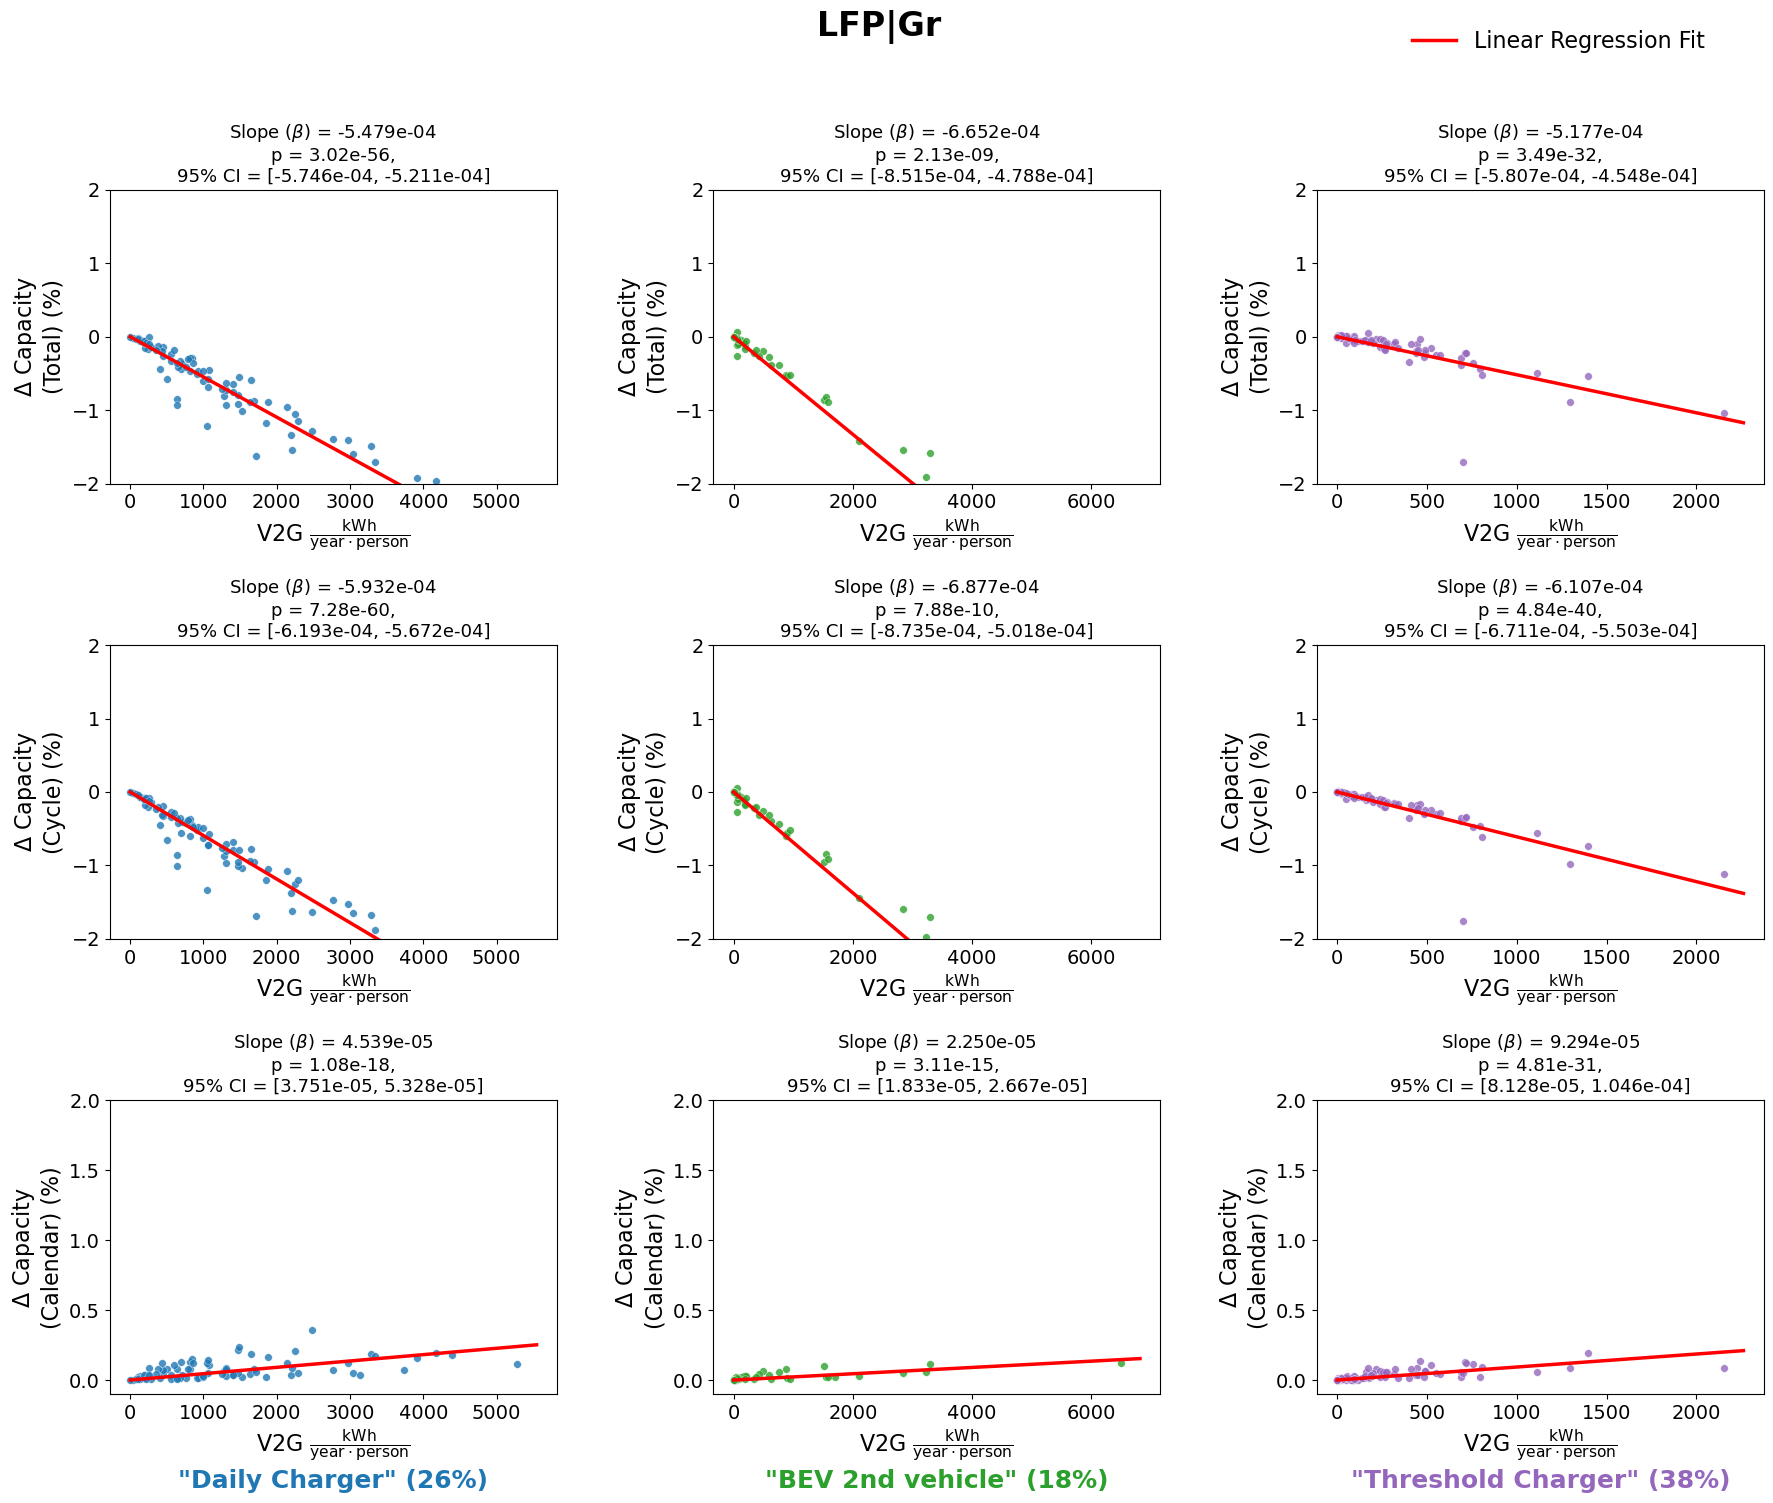

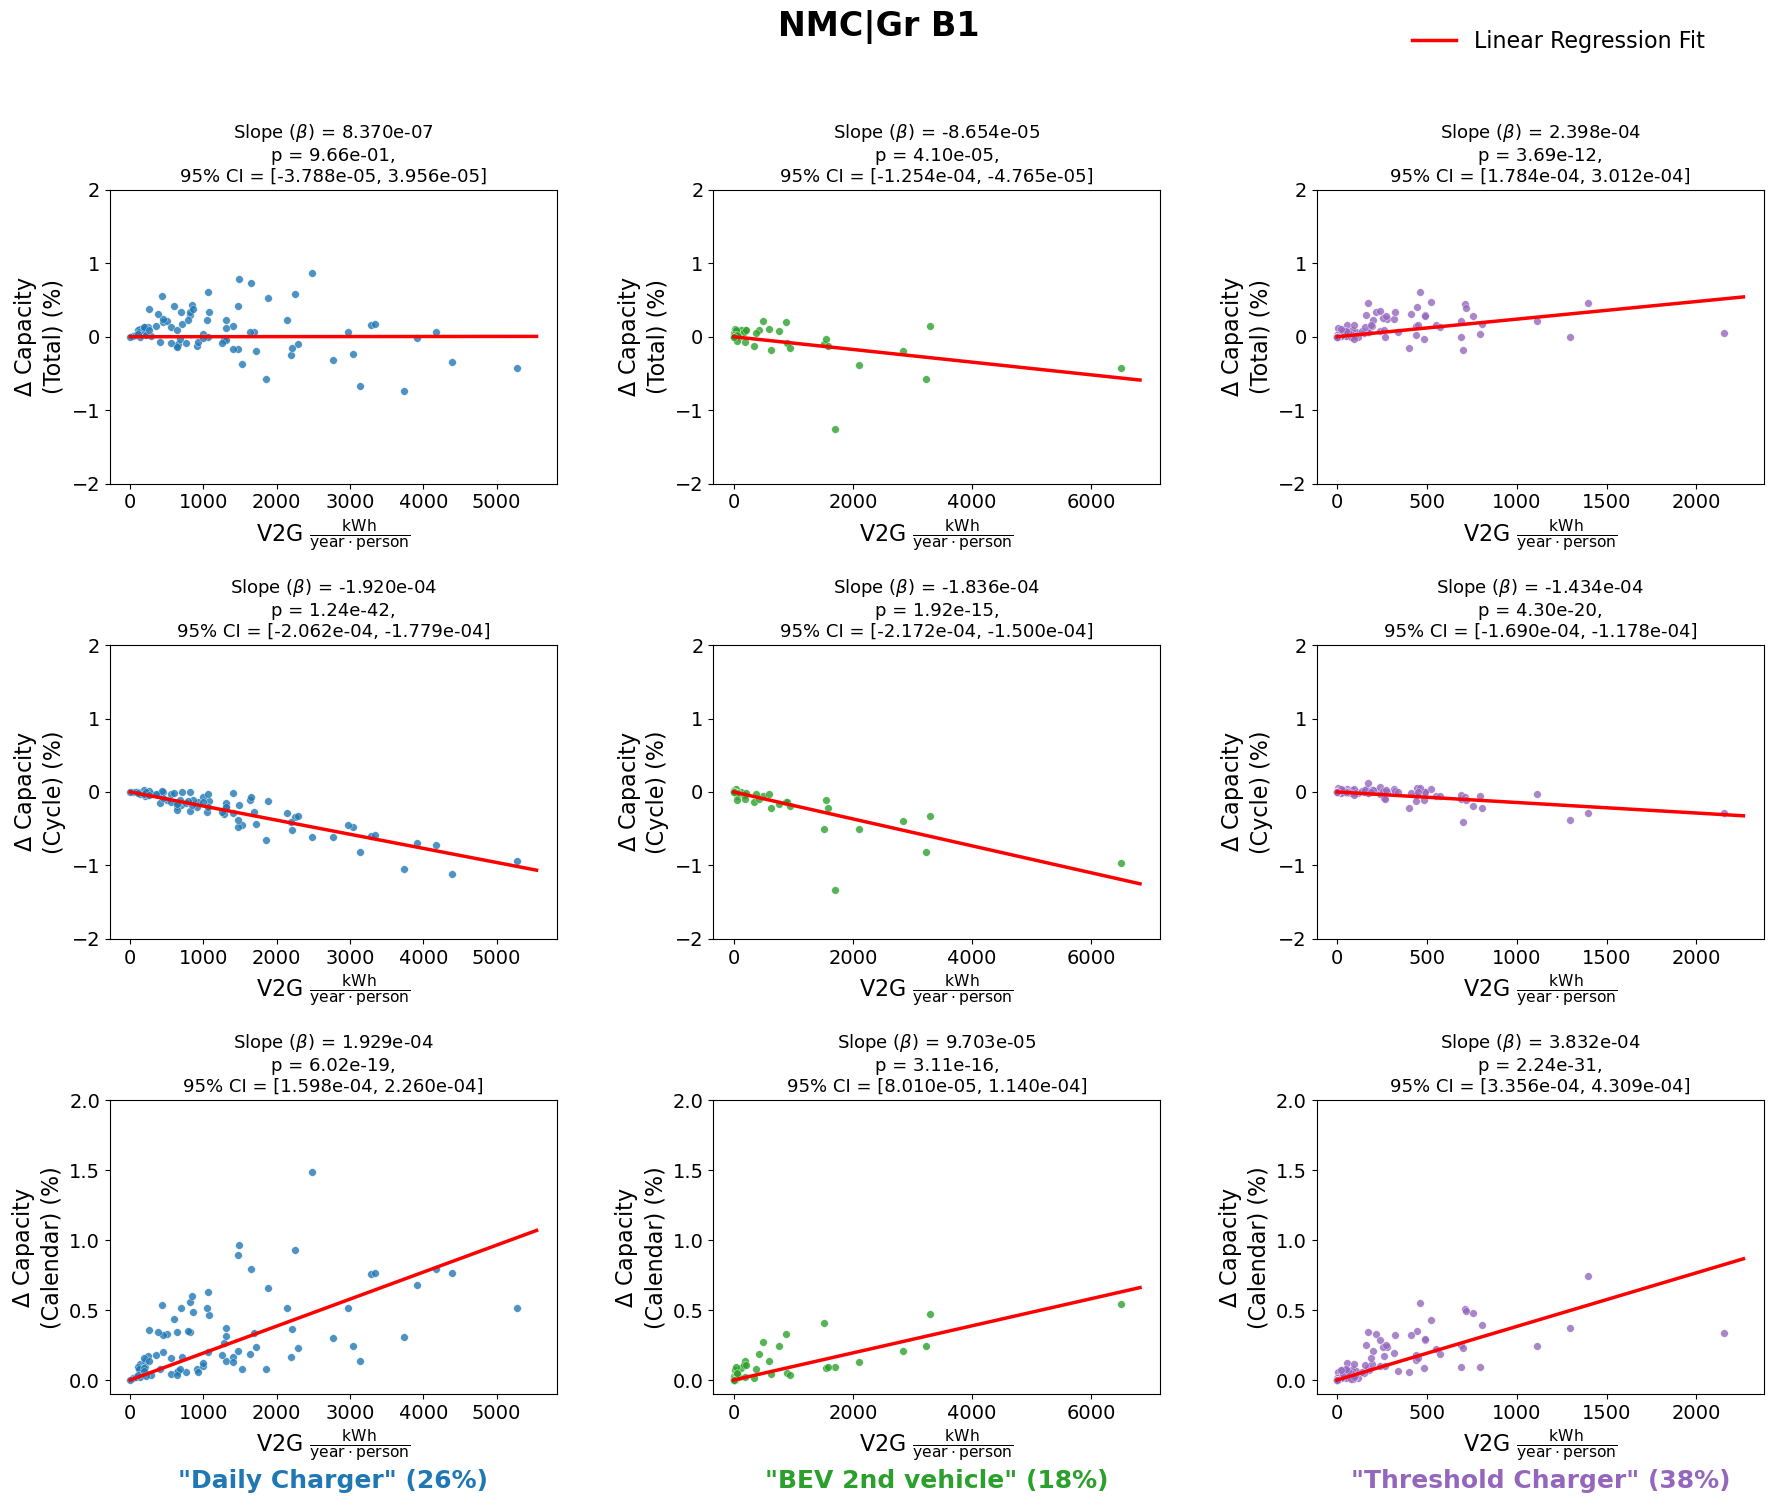

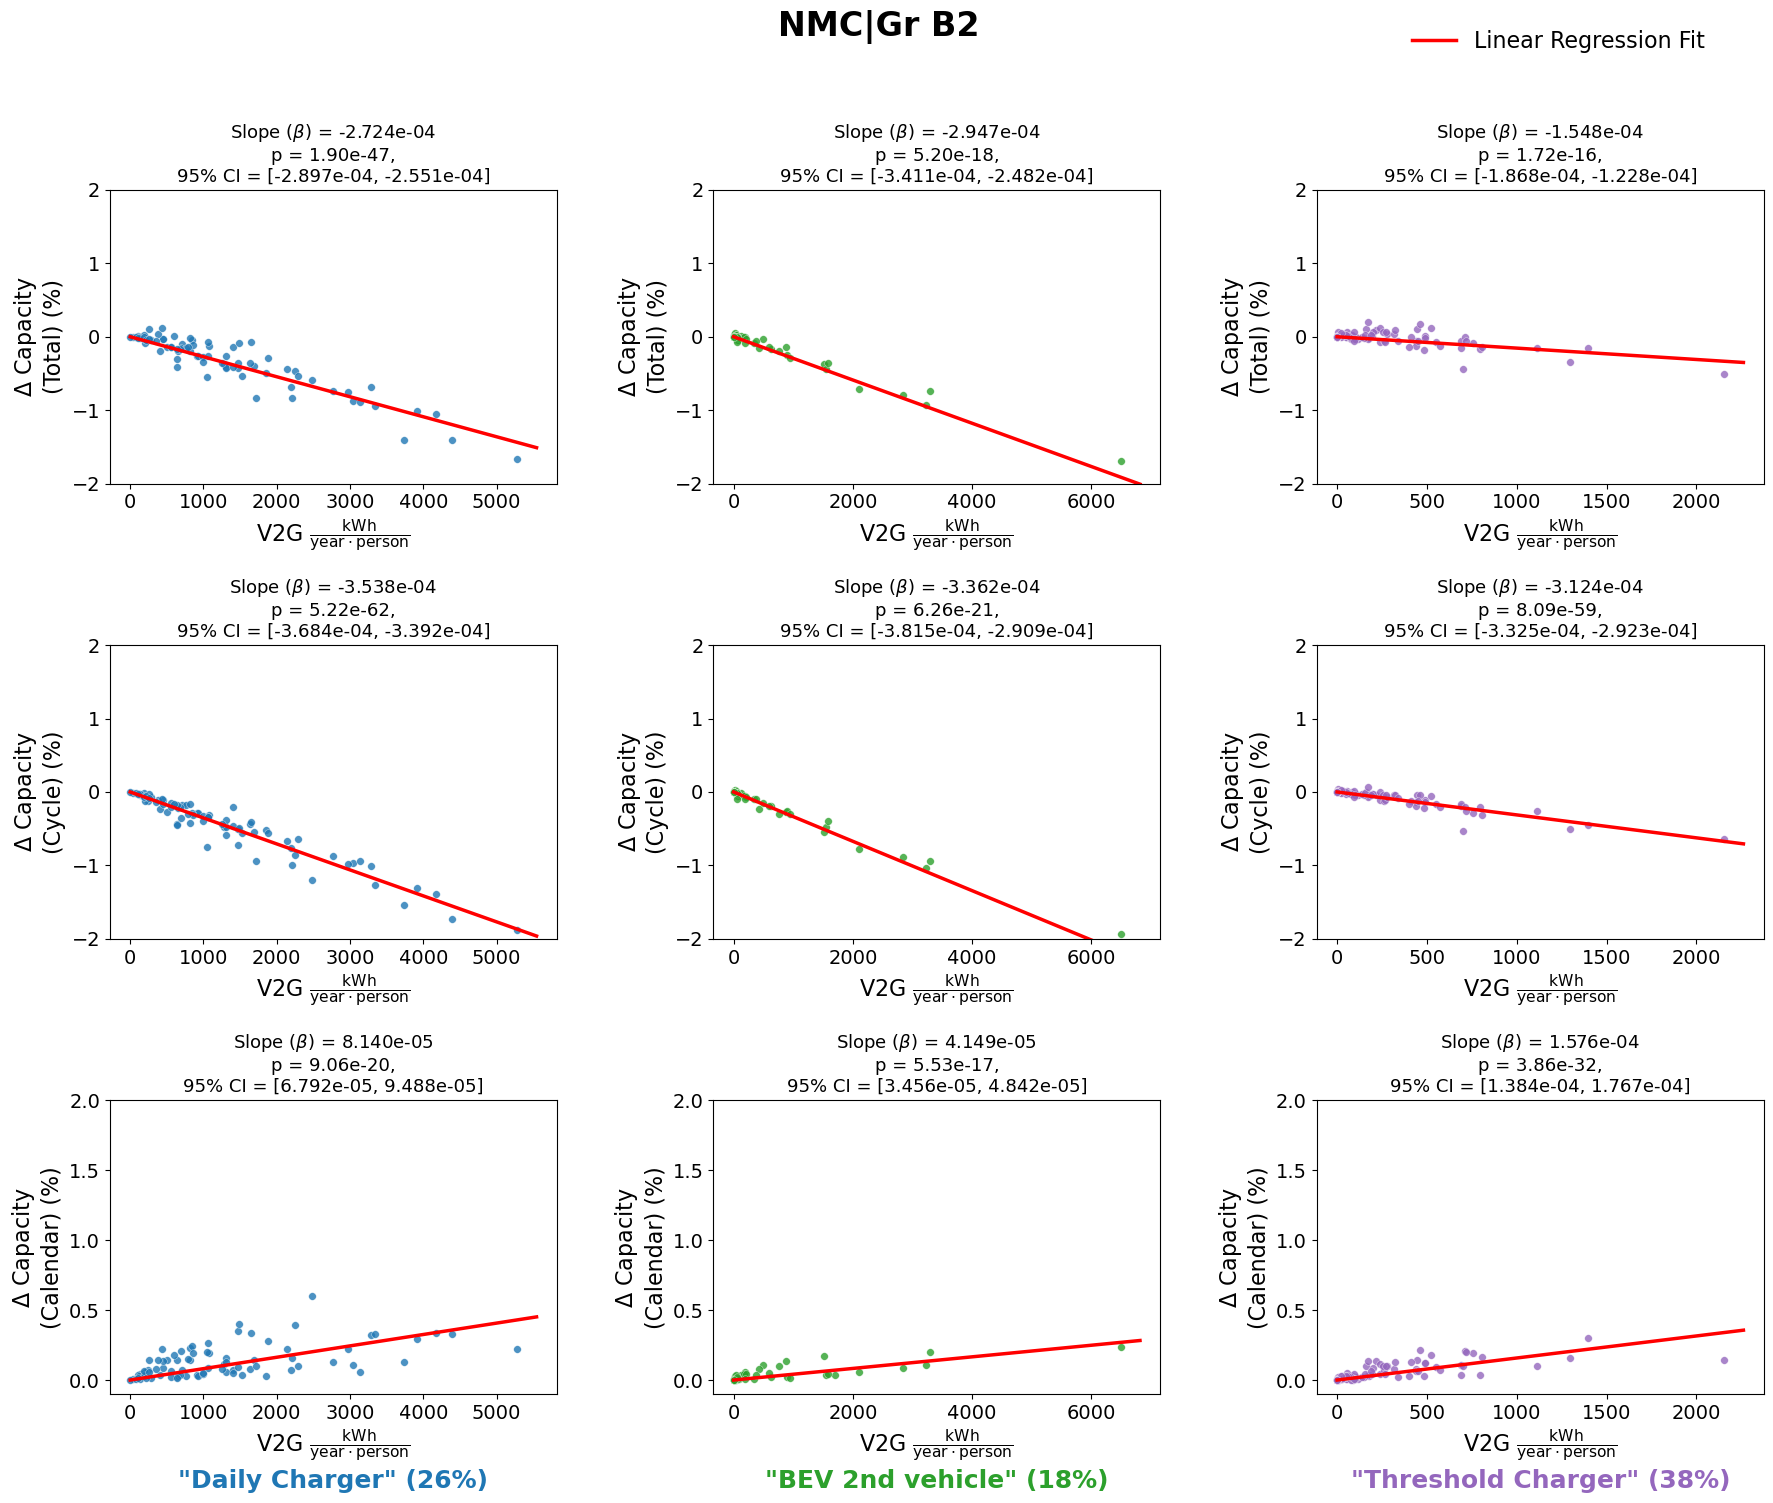

In [6]:
import statsmodels.api as sm
from matplotlib.lines import Line2D

clusters = ['Daily Charger', 'BEV 2nd vehicle', 'Threshold Charger']
colors = ['tab:blue', 'tab:green', 'tab:purple']
cluster_counts = results_df['cluster_profile'].value_counts()
total = len(results_df)

save_names = {
    "LFP|Gr": "linear_regression_LFP.pdf",
    "NMC|Gr B1": "linear_regression_NMCGrb1.pdf",
    "NMC|Gr B2": "linear_regression_NMCGrb2.pdf",
}

for chemistry in ["LFP|Gr", "NMC|Gr B1", "NMC|Gr B2"]:

    y_cols_map = {
        'Total': f'delta_q_loss_{chemistry}_10_years',
        'Cycle': f'delta_q_loss_cyc_{chemistry}_10_years',
        'Calendar': f'delta_q_loss_cal_{chemistry}_10_years',
    }

    fig, axes = plt.subplots(3, 3, figsize=(18, 16))

    for col_idx, (cluster, color) in enumerate(zip(clusters, colors)):
        subset = results_df[results_df['cluster_profile'] == cluster]
        x = subset['V2G_kwh_10_years'].to_numpy() / 10  # kWh per year

        for row_idx, (label, y_col) in enumerate(y_cols_map.items()):
            ax = axes[row_idx, col_idx]
            y = subset[y_col].to_numpy()

            # Linear regression through the origin (no intercept)
            model = sm.OLS(y, x).fit()
            slope = model.params[0]
            p_value = model.pvalues[0]
            ci_low, ci_high = model.conf_int(alpha=0.05)[0]

            # Scatter and regression line through origin
            ax.scatter(x, y, color=color, s=30, alpha=0.8, edgecolors='white', linewidths=0.3)
            x_line = np.linspace(0, x.max() * 1.05, 100)
            ax.plot(x_line, slope * x_line, color='red', linewidth=2.5)

            # Annotations as subplot title (same placement as before)
            ax.set_title(
                f"Slope ($\\beta$) = {slope:.3e}\n"
                f"p = {p_value:.2e},\n"
                f"95% CI = [{ci_low:.3e}, {ci_high:.3e}]",
                fontsize=13
            )

            # Axis labels
            ax.set_xlabel(r"V2G $\frac{\mathrm{kWh}}{\mathrm{year}}$", fontsize=16)
            ax.set_ylabel(f"$\\Delta$ Capacity\n({label}) (%)", fontsize=16)

            # Tick label sizes
            ax.tick_params(axis='both', labelsize=14)

            # Set consistent y-limits per row
            if label == 'Total' or label == 'Cycle':
                ax.set_ylim([-2.0, 2.0])
            else:
                ax.set_ylim([-0.1, 2.0])

    # Column labels at the bottom
    for col_idx, (cluster, color) in enumerate(zip(clusters, colors)):
        pct = cluster_counts[cluster] / total * 100
        axes[2, col_idx].text(
            0.5, -0.32, f'"{cluster}" ({pct:.0f}%)',
            transform=axes[2, col_idx].transAxes,
            ha='center', fontsize=18, fontweight='bold', color=color
        )

    # Overall title and legend
    fig.suptitle(chemistry, fontsize=24, fontweight='bold', y=0.99)
    legend_elements = [Line2D([0], [0], color='red', linewidth=2.5, label='Linear Regression Fit')]
    fig.legend(handles=legend_elements, loc='upper right', fontsize=16, frameon=False,
               bbox_to_anchor=(0.97, 0.99))

    plt.tight_layout(rect=[0, 0.04, 1, 0.96])
    plt.subplots_adjust(hspace=0.55, wspace=0.35)
    plt.savefig(save_names[chemistry], bbox_inches='tight', dpi=300)
    plt.show()